# Q2: Decision tree

Classify SMS messages as ham or spam. To run, place the supplied `sms.csv` beside this notebook. Required packages: NumPy, pandas, Matplotlib and scikit-learn.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

Python: 3.12.14
NumPy: 2.3.5 | pandas: 2.2.3 | scikit-learn: 1.9.1


## (a) Load and split the data

Split the raw messages into 70% training, 15% validation and 15% test, using stratification and random_state=42 in both splitting steps. Integer rounding gives 3,901, 836 and 837 rows. Fit CountVectorizer only on training text, then transform validation and test text.

In [2]:
def load_data(path='sms.csv'):
    data = pd.read_csv(path)
    assert list(data.columns) == ['label', 'message']
    assert not data.isna().any().any()
    assert set(data['label']) == {'ham', 'spam'}
    messages = data['message'].to_numpy()
    labels = data['label'].to_numpy()
    indices = np.arange(len(data))
    train_idx, holdout_idx = train_test_split(
        indices, test_size=0.30, random_state=42, stratify=labels)
    val_idx, test_idx = train_test_split(
        holdout_idx, test_size=0.50, random_state=42,
        stratify=labels[holdout_idx])
    assert len(set(train_idx) & set(val_idx)) == 0
    assert len(set(train_idx) & set(test_idx)) == 0
    assert len(set(val_idx) & set(test_idx)) == 0
    assert len(train_idx) + len(val_idx) + len(test_idx) == len(data)
    vectorizer = CountVectorizer()
    X_train = vectorizer.fit_transform(messages[train_idx])
    X_val = vectorizer.transform(messages[val_idx])
    X_test = vectorizer.transform(messages[test_idx])
    print(f'Rows: {len(data)}; exact duplicate rows beyond first: {data.duplicated().sum()}')
    print(f'Train / validation / test: {len(train_idx)} / {len(val_idx)} / {len(test_idx)}')
    print(f'Training vocabulary size: {len(vectorizer.vocabulary_)}')
    return (X_train, X_val, X_test, labels[train_idx], labels[val_idx],
            labels[test_idx], vectorizer)

X_train, X_val, X_test, y_train, y_val, y_test, vectorizer = load_data()
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
print('Training label counts:', pd.Series(y_train).value_counts().to_dict())
print(f'Training majority-class baseline: {np.mean(y_train == "ham"):.2%}')

Rows: 5574; exact duplicate rows beyond first: 403
Train / validation / test: 3901 / 836 / 837
Training vocabulary size: 7179
Training label counts: {'ham': 3378, 'spam': 523}
Training majority-class baseline: 86.59%


## (b) Select the tree depth

Compare ten depths using a manual validation loop. Each tree uses the default Gini criterion and random_state=42. Select the highest validation accuracy; tied scores choose the smaller depth. The test set is not used to choose a model.

max_depth  validation_accuracy
        1  87.440191%
        2  92.583732%
        3  94.617225%
        5  95.095694%
       10  97.009569%
       15  97.488038%
       20  97.488038%
       30  97.607656%
       40  97.368421%


       50  97.607656%
Best max_depth: 30; validation accuracy: 97.607656%


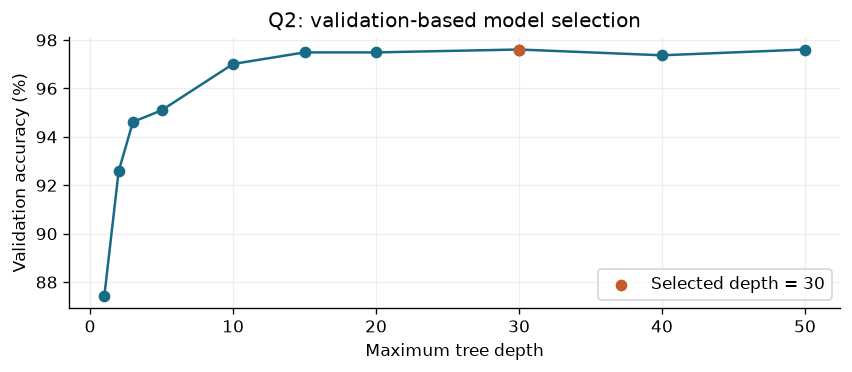

In [3]:
depths = [1, 2, 3, 5, 10, 15, 20, 30, 40, 50]

def select_model(X_train, y_train, X_val, y_val, depths):
    best_model, best_depth, best_accuracy = None, None, -1.0
    rows = []
    print('max_depth  validation_accuracy')
    for depth in sorted(set(depths)):
        model = DecisionTreeClassifier(max_depth=depth, random_state=42)
        model.fit(X_train, y_train)
        predictions = model.predict(X_val)
        accuracy = float(np.mean(predictions == y_val))
        rows.append({'max_depth': depth, 'validation_accuracy': accuracy})
        print(f'{depth:9d}  {accuracy:.6%}')
        if accuracy > best_accuracy:
            best_model, best_depth, best_accuracy = model, depth, accuracy
    print(f'Best max_depth: {best_depth}; validation accuracy: {best_accuracy:.6%}')
    return best_model, pd.DataFrame(rows)

best_model, validation_results = select_model(X_train, y_train, X_val, y_val, depths)
best_depth = best_model.max_depth
best_validation_accuracy = float(validation_results['validation_accuracy'].max())
fig, ax = plt.subplots(figsize=(7.2, 3.2))
ax.plot(validation_results['max_depth'], validation_results['validation_accuracy'] * 100,
        marker='o', color='#176b87')
ax.scatter([best_depth], [best_validation_accuracy * 100], color='#c45b28',
           zorder=3, label=f'Selected depth = {best_depth}')
ax.set(xlabel='Maximum tree depth', ylabel='Validation accuracy (%)', title='Q2: validation-based model selection')
ax.grid(alpha=.2)
ax.legend()
plt.tight_layout()
plt.show()

## Test accuracy

Evaluate the selected training-fitted model once on the test set, without refitting.

In [4]:
test_predictions = best_model.predict(X_test)
test_correct = int(np.sum(test_predictions == y_test))
test_accuracy = test_correct / len(y_test)
print(f'Selected max_depth: {best_depth}')
print(f'Best validation accuracy: {best_validation_accuracy:.6%}')
print(f'Final test accuracy: {test_accuracy:.6%} ({test_correct}/{len(y_test)})')

Selected max_depth: 30
Best validation accuracy: 97.607656%
Final test accuracy: 96.535245% (808/837)


## (c) First two layers

The diagram shows the root and its children. The text also includes depth 2 for context. A word-count threshold of 0.5 separates messages without the word from messages containing it.

|--- call <= 0.50
|   |--- txt <= 0.50
|   |   |--- www <= 0.50
|   |   |   |--- truncated branch of depth 28
|   |   |--- www >  0.50
|   |   |   |--- truncated branch of depth 2
|   |--- txt >  0.50
|   |   |--- to <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- to >  0.50
|   |   |   |--- truncated branch of depth 3
|--- call >  0.50
|   |--- me <= 0.50
|   |   |--- ll <= 0.50
|   |   |   |--- truncated branch of depth 25
|   |   |--- ll >  0.50
|   |   |   |--- class: ham
|   |--- me >  0.50
|   |   |--- stop <= 0.50
|   |   |   |--- class: ham
|   |   |--- stop >  0.50
|   |   |   |--- truncated branch of depth 2



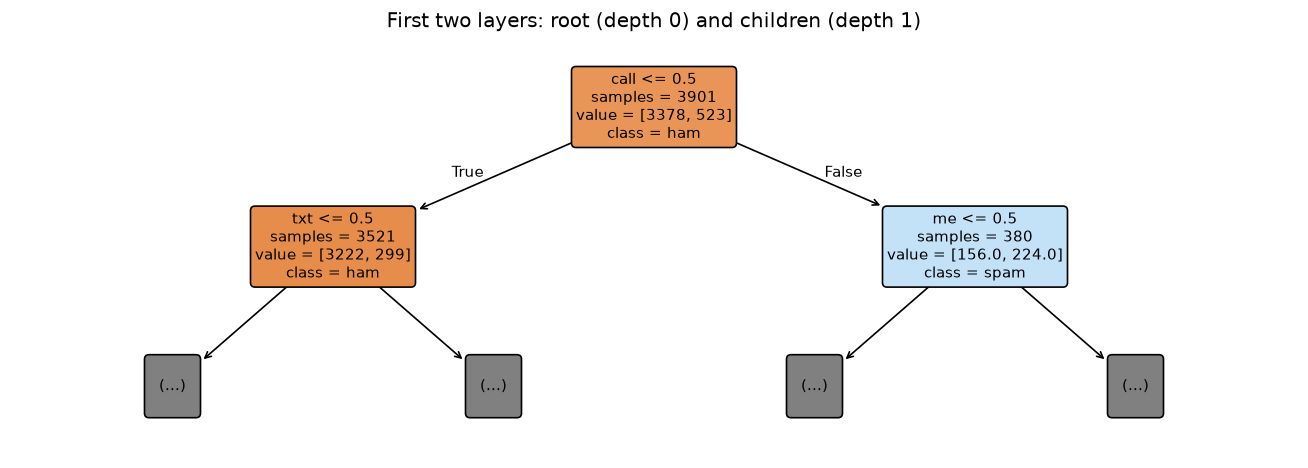

Root split: count('call') <= 0.50


In [5]:
feature_names = vectorizer.get_feature_names_out()
tree_text = export_text(best_model, feature_names=list(feature_names), max_depth=2, decimals=2)
print(tree_text)
fig, ax = plt.subplots(figsize=(11, 4))
plot_tree(best_model, feature_names=feature_names, class_names=best_model.classes_,
          max_depth=1, filled=True, rounded=True, impurity=False, fontsize=9, ax=ax)
ax.set_title('First two layers: root (depth 0) and children (depth 1)')
plt.tight_layout()
plt.show()
root_word = feature_names[best_model.tree_.feature[0]]
root_threshold = float(best_model.tree_.threshold[0])
print(f'Root split: count({root_word!r}) <= {root_threshold:.2f}')

## Comment on the root split

The root splits on the word "call". This makes sense because promotional messages may ask the recipient to call a number. Legitimate messages also use this word, so later splits are needed.

## Results

Depths 30 and 50 tie at 97.6077% validation accuracy. The smaller depth, 30, is selected. Test accuracy is 96.5352% (808 of 837 correct).

Ham makes up 86.6% of the dataset. Accuracy alone does not describe how well spam is detected. The supplied data also contains 403 duplicate rows beyond their first occurrences. These are retained, but identical messages may appear in different splits.

Data: supplied SMS Spam Collection CSV. Uses scikit-learn CountVectorizer and DecisionTreeClassifier.